# 1D Convection-Diffusion with the Upwind Scheme
### CFD Homework (Week 9)
Juliano B12202031

Date: Wed, Nov 4th, 2026 · Due: 12pm Sun, Nov 8th, 2026

Complete source code (frozen for this assignment): [github.com/anojewel/siefdi/tree/assignment-4](https://github.com/anojewel/siefdi/tree/assignment-4)

In [90]:
%load_ext autoreload
%autoreload 2

import os
# Run from the siefdi/ folder so `src` can be imported, even if the kernel starts in notebooks/
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

import numpy as np
import inspect
import matplotlib.pyplot as plt

from src.geometry import RectangleSpace, CellCentredGrid
from src.fields import InternalScalarField, SimpleWallBC
from src.matrix_solver import SystemLinearEquations
from src.fvm import Diffusion, Convection

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Problem statement

A property $\phi$ is transported by the 1-dimensional convection and diffusion equation:
$$ \frac{d}{dx}(\rho u \phi) = \frac{d}{dx}\left(\Gamma \frac{d\phi}{dx}\right) $$

The rod runs from $x = 0$ to $x = L$ with flow velocity $u$ in the $+x$ direction.

Boundary conditions:
- At $x = 0$: $\phi = 1$
- At $x = L$: $\phi = 0$

Using **5 equally spaced cells**, calculate the distribution of $\phi$ as a function of $x$ using the **upwind scheme** for

1. Case 1: $u = 0.1\,\mathrm{m/s}$
2. Case 2: $u = 2.5\,\mathrm{m/s}$

Compare with the analytical solution:
$$ \frac{\phi - \phi_0}{\phi_L - \phi_0} = \frac{\exp\left(\dfrac{\rho u x}{\Gamma}\right) - 1}{\exp\left(\dfrac{\rho u L}{\Gamma}\right) - 1}, \qquad P = \frac{\rho u L}{\Gamma} $$

Data: $L = 1\,\mathrm{m}$, $\rho = 1\,\mathrm{kg/m^3}$, $\Gamma = 0.1\,\mathrm{kg/m/s}$.

## Setup

In [91]:
L = 1.0       # m
rho = 1.0     # kg/m^3
Gamma = 0.1   # kg/m/s
phi_0, phi_L = 1.0, 0.0
N = 5
u_1 = 0.1     # m/s, case 1
u_2 = 2.5     # m/s, case 2

We make the 1D rod using syntax similar to Assignment 1.

In [92]:
# L = 1 m and mesh, 5 equally spaced cells:
rod_gridded = RectangleSpace([[0,L],[0,0.1],[0,0.1]]).grid('cell',[N])


These values are stored in the modules of the `Grid` in `geometry.py`. `[0]` to just show the $x$ dimension:

In [93]:
print("faces   x_{i±1/2}:", rod_gridded.faces[0])
print("nodes   x_i      :", rod_gridded.centres[0])
print("δx      (centre_spacing):", rod_gridded.centre_spacing[0])
print("Δx      (cell_lengths)  :", rod_gridded.cell_lengths[0])

faces   x_{i±1/2}: [0.  0.2 0.4 0.6 0.8 1. ]
nodes   x_i      : [0.1 0.3 0.5 0.7 0.9]
δx      (centre_spacing): [0.1 0.2 0.2 0.2 0.2 0.1]
Δx      (cell_lengths)  : 0.2


Build the $\phi$ field as an object in `InternalScalarField` with corresponding boundary conditions:

In [94]:
# Dirichlet at both x ends: phi = 1 at x = 0 and phi = 0 at x = L
# The y and z walls are insulated (zero slope), so the problem stays 1D
rod_ends = SimpleWallBC(
    wall_values = [[phi_0, phi_L],[0,0],[0,0]],
    derivative_order= [[0,0],[1,1],[1,1]]
)

In [95]:
phi_field = InternalScalarField(
    grid=rod_gridded,
    bcs=rod_ends
)

Building up from previous assignments, the diffusion term values is stored in 'Diffusion'

In [96]:
rod_diffterm = Diffusion(phi_field,Gamma)

## Upwind scheme derivation

Steady diffusion-convection equation:
$$\frac{d}{dx}(\rho u \phi) = \frac{d}{dx}\left(\Gamma \frac{d\phi}{dx}\right)$$

Integrate from the west face to the east face:
$$\int_w^ed(\rho u \phi) = \int_w^e d\left(\Gamma \frac{d\phi}{dx}\right)$$

$$(\rho u\phi)_e-(\rho u \phi)_w=\left(\Gamma \dfrac{d\phi}{dx}\right)_e-\left(\Gamma \dfrac{d\phi}{dx}\right)_w$$

Solve the diffusion part using piecewise-linear approximation at the face.
$$\left(\Gamma \dfrac{d\phi}{dx}\right)_e-\left(\Gamma \dfrac{d\phi}{dx}\right)_w =\Gamma_e\left( \frac{\phi_E-\phi_P}{(\delta x)_e}\right)-\Gamma_w\left( \frac{\phi_P-\phi_W}{(\delta x)_w}\right)$$

$$D_i\equiv\dfrac{\Gamma_i}{(\delta x)_i}\implies D_e\phi_E+D_w\phi_W-(D_e+D_w)\phi_P$$

Solve the convection part. Let $\rho_i u _i \equiv F_i$. Therefore,
$$ (\rho u\phi)_e-(\rho u \phi)_w=F_e\phi_e - F_w\phi_w$$

The equation above is per unit area. In the code I keep the cross-section area $A$ in both terms:
$$ D_i = \frac{\Gamma_i A}{(\delta x)_i}, \qquad F_i = \rho_i u_i A $$
In 1D every face has the same $A$, so dividing the whole equation by $A$ gives back the per-unit-area form, and $\phi$ comes out the same. The Peclet number $F/D$ doesn't change either, since $A$ cancels. I keep $A$ so that $F$ is the real mass flow through the face in $\mathrm{kg/s}$, and so the code still works in 2D/3D, where faces normal to different axes have different areas.

$F_i$ is stored in `Convection.fluxes`. $\rho$ is `Convection.coefficient` and $u$ is `Convection.velocity`. $\rho$, $u$ and $A$ are constant, so it is one value for every face.

In [97]:
print(inspect.getsource(Convection.fluxes))

    def fluxes(self):
        g = self.field.grid
        rho = self.coefficient
        u = self.velocity
        # FORMULA IS APPLIED HERE
        F = rho*u*g.areas[0]
        return F



In [98]:
rod_convterm_1 = Convection(phi_field, rho, u_1)
rod_convterm_2 = Convection(phi_field, rho, u_2)
print(f"F case 1 (u = {u_1} m/s): {rod_convterm_1.fluxes()}")
print(f"F case 2 (u = {u_2} m/s): {rod_convterm_2.fluxes()}")

F case 1 (u = 0.1 m/s): 0.0010000000000000002
F case 2 (u = 2.5 m/s): 0.025000000000000005


Definition of the **upwind scheme**:
$$\phi_e=\begin{cases}\phi_E,\quad&u_e<0\\\phi_P,\quad&u_e>0\end{cases}\,,\quad\phi_w=\begin{cases}\phi_P,\quad&u_w<0\\\phi_W,\quad&u_w>0\end{cases}$$


Can be simplified as:
$$F_e\phi_e = \phi_P\max(F_e,0)+\phi_E\min(F_e,0)\quad F_w\phi_w=\phi_W \max(F_w,0)+\phi_P\min(F_w,0)$$

Thus the final equation becomes:
$$\phi_E\min(F_e,0)-\phi_W \max(F_w,0)+\phi_P[\max(F_e,0)-\min(F_w,0)]=$$
$$D_e\phi_E+D_w\phi_W-(D_e+D_w)\phi_P $$

$$a_P\phi_P = a_E\phi_E +a_W\phi_W$$
$$\begin{aligned}
a_P &= D_e+D_w+\max(F_e,0)-\min(F_w,0)=D_e+D_w+\max(F_e,0)+\max(-F_w,0)\\
a_E &= D_e-\min(F_e,0)=D_e+\max(-F_e,0)\\
a_W &= D_w+\max(F_w,0) \end{aligned}$$

Notice the red parts are the matrix assembled from the diffusion coefficients:
$$\begin{aligned}
a_P &= {\color{red}D_e+D_w}+\max(F_e,0)+\max(-F_w,0)\\
a_E &= {\color{red}D_e}+\max(-F_e,0)\\
a_W &= {\color{red}D_w}+\max(F_w,0) \end{aligned}
\implies
\begin{aligned}
a_P &= {\color{red} a_P^\text{diffusion}}+\max(F_e,0)+\max(-F_w,0)\\
a_E &= {\color{red} a_E^\text{diffusion}}+\max(-F_e,0)\\
a_W &= {\color{red} a_W^\text{diffusion}}+\max(F_w,0) \end{aligned}
$$

The values are stored in `Diffusion.matrix()`

In [99]:
print(inspect.getsource(Diffusion.matrix))
diffterm_matrix = rod_diffterm.matrix()
print(f"\n {diffterm_matrix}")

    def matrix(self):
        ### A. Assemble A matrix
        # 1. Take the list for just one dimensional diffusion conductances (x-direction)
        diffconds_1d = self.conductances()[0]
        
        # 2. Make diagonal with A_{ii} = D_{i} + D_{i+1}
        matrix_diagonal = np.diag([diffconds_1d[i] + diffconds_1d[i+1] for i in range(len(diffconds_1d)-1)])

        # 3. Make off diagonal parts
        matrix_up_offdiag = np.diag([-diffconds_1d[i+1] for i in range(len(diffconds_1d)-2)],1)
    
        # 4. Combine them to get our target matrix (our result A)
        A= matrix_diagonal + matrix_up_offdiag + matrix_up_offdiag.T

        # 5. Check for Neumann
        f = self.field
        if f.bcs.derivative_order[0,0] == 1:
            A[0,0] = diffconds_1d[1]
        if f.bcs.derivative_order[0,1] == 1:
            A[-1,-1] = diffconds_1d[-2]

        return A


 [[ 0.015 -0.005  0.     0.     0.   ]
 [-0.005  0.01  -0.005  0.     0.   ]
 [ 0.    -0.005  0.01  -0.005  0.   ]
 [ 0

Since the leftover terms are informations solely dependent on the convection term, we naturally define them as the convection term matrix
$$ \begin{aligned}
a_P^\text{convection} &= \max(F_e,0)+\max(-F_w,0)\\
a_E^\text{convection} &= \max(-F_e,0)\\
a_W^\text{convection} &= \max(F_w,0)
\end{aligned}$$

The convection matrix is stored in `Convection.matrix()`. For $u>0$: $F$ on the diagonal, $-F$ below it.

In [100]:
print(inspect.getsource(Convection.matrix))

    def matrix(self):
        F = self.fluxes()
        g = self.field.grid
        N = g.shape[0]
        # FORMULA IS HERE
        aP = max(F, 0) + max(-F, 0)
        aE = max(-F, 0)
        aW = max(F, 0)

        M = (np.diag(aP * np.ones(N))            # main diagonal, N entries
            + np.diag(-aE * np.ones(N - 1), 1)   # above: east neighbour, N-1 entries
            + np.diag(-aW * np.ones(N - 1), -1)) # below: west neighbour, N-1 entries
        return M



In [101]:
print(f"Convection matrix, case 1 (u = {u_1} m/s):\n{rod_convterm_1.matrix()}")
print(f"Convection matrix, case 2 (u = {u_2} m/s):\n{rod_convterm_2.matrix()}")

Convection matrix, case 1 (u = 0.1 m/s):
[[ 0.001  0.     0.     0.     0.   ]
 [-0.001  0.001  0.     0.     0.   ]
 [ 0.    -0.001  0.001  0.     0.   ]
 [ 0.     0.    -0.001  0.001  0.   ]
 [ 0.     0.     0.    -0.001  0.001]]
Convection matrix, case 2 (u = 2.5 m/s):
[[ 0.025  0.     0.     0.     0.   ]
 [-0.025  0.025  0.     0.     0.   ]
 [ 0.    -0.025  0.025  0.     0.   ]
 [ 0.     0.    -0.025  0.025  0.   ]
 [ 0.     0.     0.    -0.025  0.025]]


## Boundary Terms

Let boundary terms be $\phi(0)=\phi_0$ and  $\phi(L)=\phi_L$. We know that $x=0$ is a wall. For $P$ as the leftmost grid centre:
$$a_P\phi_P = a_E\phi_E +a_W\phi_W\implies a_P\phi_P-a_E\phi_E=\underbrace{a_W\phi_0}_\text{known}$$
Since the rhs is known we can treat it as the component of the right-hand-side known vector.

Do the same for $P$ as the rightmost grid:
$$a_P\phi_P = a_E\phi_E +a_W\phi_W\implies a_P\phi_P-a_W\phi_W=a_E\phi_L$$

For the rest of the grid it looks like this:
$$ a_P\phi_P -a_E\phi_E -a_W\phi_W=0 $$

The known right hand side vector component is zero. Thus the right hand side, written as a vector have only values on the top and bottom. Then we decompose them into diffusive and convective terms:
$$\boldsymbol \phi_\text{known}=\begin{bmatrix}
a_W\phi_0\\
0\\
\vdots\\
0\\
a_E\phi_L
\end{bmatrix}=
\underbrace{\begin{bmatrix} D_w\phi_0\\ 0\\ \vdots\\ 0\\ D_e\phi_L\end{bmatrix}}_{\boldsymbol\phi_\text{known}^\text{diffusion}}
+
\underbrace{\begin{bmatrix} \max(F_w,0)\,\phi_0\\ 0\\ \vdots\\ 0\\ \max(-F_e,0)\,\phi_L\end{bmatrix}}_{\boldsymbol\phi_\text{known}^\text{convection}}$$

The diffusion part $\boldsymbol\phi_\text{known}^\text{diffusion}$ is stored in `Diffusion.source_vector()`, same as the previous assignments:

In [102]:
print(inspect.getsource(Diffusion.source_vector))

    def source_vector(self):
        diffconds_1d = self.conductances()[0]
        ### B. Assemble b vector
        # Get wall temp
        wall_values = self.field.bcs.wall_values
        left_end = diffconds_1d[0]*wall_values[0,0]
        right_end = diffconds_1d[-1]*wall_values[0,1]
        b = np.concatenate([[left_end],np.zeros(self.field.grid.shape[0]-2),[right_end]])

        # Check for Neumann:
        f = self.field
        g = f.grid
        if f.bcs.derivative_order[0,0] == 1:
            b[0] = -diffconds_1d[0] * f.bcs.wall_values[0,0] *g.centre_spacing[0][0]
        if f.bcs.derivative_order[0,1] == 1:
            b[-1] = diffconds_1d[-1] * f.bcs.wall_values[0,1] *g.centre_spacing[0][-1]

        return b



In [103]:
print(f"Diffusion known vector: {rod_diffterm.source_vector()}")

Diffusion known vector: [0.01 0.   0.   0.   0.  ]


The convection part $\boldsymbol\phi_\text{known}^\text{convection}$ is stored in `Convection.source_vector()`. Only the upwind wall carries a value in: for $u>0$ that is the west wall, so the last entry is zero.

In [104]:
print(inspect.getsource(Convection.source_vector))

from .matrix_solver import SystemLinearEquations



In [105]:
print(f"Convection known vector, case 1 (u = {u_1} m/s): {rod_convterm_1.source_vector()}")
print(f"Convection known vector, case 2 (u = {u_2} m/s): {rod_convterm_2.source_vector()}")

Convection known vector, case 1 (u = 0.1 m/s): [0.001 0.    0.    0.    0.   ]
Convection known vector, case 2 (u = 2.5 m/s): [0.025 0.    0.    0.    0.   ]


## Case 1: $u = 0.1$ m/s

From the boundary terms, the whole system is the diffusion part plus the convection part, for both the matrix and the known vector:
$$\left(\mathbf A^\text{diffusion}+\mathbf A^\text{convection}\right)\boldsymbol\phi = \boldsymbol\phi_\text{known}^\text{diffusion}+\boldsymbol\phi_\text{known}^\text{convection}$$
First, adding the two matrices:

In [106]:
# Combine the matrices: diffusion + convection (u = 0.1 m/s)
A_case1 = rod_diffterm.matrix() + rod_convterm_1.matrix()
print(A_case1)

[[ 0.016 -0.005  0.     0.     0.   ]
 [-0.006  0.011 -0.005  0.     0.   ]
 [ 0.    -0.006  0.011 -0.005  0.   ]
 [ 0.     0.    -0.006  0.011 -0.005]
 [ 0.     0.     0.    -0.006  0.016]]


With $D = 0.005$ (interior), $D = 0.01$ (wall faces) and $F = 0.001$, every row gets $+F$ on the diagonal and $-F$ on the west neighbour:
$$
\mathbf A =
\begin{bmatrix}
0.016 & -0.005 & 0 & 0 & 0 \\
-0.006 & 0.011 & -0.005 & 0 & 0 \\
0 & -0.006 & 0.011 & -0.005 & 0 \\
0 & 0 & -0.006 & 0.011 & -0.005 \\
0 & 0 & 0 & -0.006 & 0.016
\end{bmatrix}
$$
Note that unlike the diffusion matrix, this one is not symmetric anymore: the flow goes to the right, so the west neighbour weighs more than the east neighbour.

Next, adding the two known vectors:

In [107]:
# Combine the known vectors: diffusion + convection
b_case1 = rod_diffterm.source_vector() + rod_convterm_1.source_vector()
print(b_case1)

[0.011 0.    0.    0.    0.   ]


Only the first entry is non-zero: $D_w\phi_0 + \max(F_w,0)\,\phi_0 = (0.01 + 0.001)\cdot 1 = 0.011$. The last entry is zero since $\phi_L = 0$.

From Assignment 2 we already have a TDMA solver inside `matrix_solver.py`. TDMA works here because:
- $\mathbf A^\text{convection}$ only adds to the diagonal and the one below it, so $\mathbf A$ is still tridiagonal.
- Upwind keeps every row diagonally dominant, $a_P \ge a_E + a_W$: $0.016 > 0.005$ in the first row, $0.011 = 0.006 + 0.005$ in the interior rows and $0.016 > 0.006$ in the last row.

Store the problem inside `SystemLinearEquations` and solve:

In [108]:
sle_case1 = SystemLinearEquations(
    matrix = A_case1,
    rhs_vector = b_case1
)
# Solve with TDMA
phi_case1 = sle_case1.thomas().unknown_vector
print(f"phi case 1: {phi_case1}")

phi case 1: [0.93373341 0.7879469  0.6130031  0.40307053 0.15115145]


To check the solution, the residual $\mathbf A\boldsymbol\phi - \boldsymbol\phi_\text{known}$ should be zero (up to rounding):

In [109]:
print(f"residual: {sle_case1.residual()}")

residual: [-1.73472348e-18  1.23202961e-18 -2.82150982e-19 -2.90948750e-19
 -3.33714182e-19]


## Case 2: $u = 2.5$ m/s

Same steps as Case 1, only the convection term changes to `rod_convterm_2` ($u = 2.5\,\mathrm{m/s}$). Now $F = 0.025$ is 5 times bigger than the interior $D = 0.005$, so convection dominates. Combining the matrices and the known vectors:

In [115]:
A_case2 = rod_diffterm.matrix() + rod_convterm_2.matrix()
b_case2 = rod_diffterm.source_vector() + rod_convterm_2.source_vector()
print(A_case2)
print(b_case2)

[[ 0.04  -0.005  0.     0.     0.   ]
 [-0.03   0.035 -0.005  0.     0.   ]
 [ 0.    -0.03   0.035 -0.005  0.   ]
 [ 0.     0.    -0.03   0.035 -0.005]
 [ 0.     0.     0.    -0.03   0.04 ]]
[0.035 0.    0.    0.    0.   ]


Every row gets $+0.025$ on the diagonal and $-0.025$ on the west neighbour, so the diagonal is $0.040$ at the walls and $0.035$ in the interior, $-0.030$ below it and $-0.005$ above it. The west neighbour now weighs 6 times more than the east neighbour, almost everything comes from upstream. The known vector is $(0.01 + 0.025)\cdot 1 = 0.035$ in the first entry and zero elsewhere.

It is still tridiagonal and still diagonally dominant ($0.035 = 0.030 + 0.005$ in the interior rows), so TDMA works the same way as Case 1:

In [111]:

sle_case2 = SystemLinearEquations(
    matrix = A_case2,
    rhs_vector = b_case2
)
phi_case2 = sle_case2.thomas().unknown_vector
print(f"phi case 2: {phi_case2}")
print(f"residual: {sle_case2.residual()}")

phi case 2: [0.99984252 0.99874016 0.99212598 0.95244094 0.71433071]
residual: [-6.93889390e-18  3.20636999e-18 -2.95063624e-18  2.27736137e-18
 -2.35887425e-18]


## Comparison with the analytical solution

The analytical solution is given in the problem statement. Solving it for $\phi$:
$$\phi(x) = \phi_0 + (\phi_L - \phi_0)\,\frac{\exp(\rho u x/\Gamma) - 1}{\exp(\rho u L/\Gamma) - 1}$$
We evaluate it at the node positions $x_i$ so it can be compared with the numerical $\phi_i$ directly, and on a fine grid for the plot:


In [112]:

def analytical_phi(x, u, rho, Gamma, L, phi_0, phi_L):
    P = rho * u * L / Gamma
    return phi_0 + (phi_L - phi_0) * (np.exp(P * x / L) - 1) / (np.exp(P) - 1)

xs = rod_gridded.centres[0]
x_plot = np.linspace(0, L, 200)
cases = [(u_1, phi_case1), (u_2, phi_case2)]

for u, phi_num in cases:
    print(f"u = {u} m/s")
    print("  FVM upwind :", np.round(phi_num, 4))
    print("  analytical :", np.round(analytical_phi(xs, u, rho, Gamma, L, phi_0, phi_L), 4))

u = 0.1 m/s
  FVM upwind : [0.9337 0.7879 0.613  0.4031 0.1512]
  analytical : [0.9388 0.7964 0.6225 0.41   0.1505]
u = 2.5 m/s
  FVM upwind : [0.9998 0.9987 0.9921 0.9524 0.7143]
  analytical : [1.     1.     1.     0.9994 0.9179]


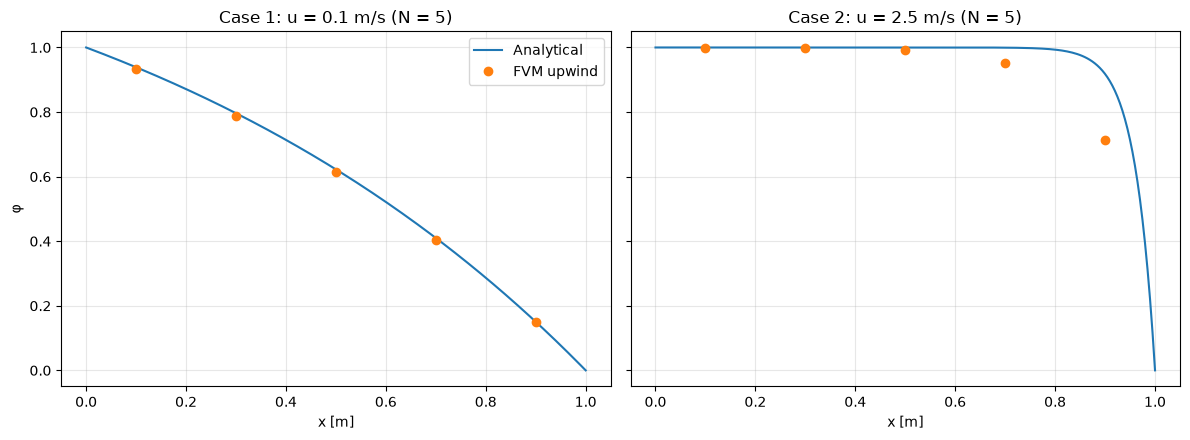

In [113]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for k, (u, phi_num) in enumerate(cases):
    ax = axes[k]
    ax.plot(x_plot, analytical_phi(x_plot, u, rho, Gamma, L, phi_0, phi_L), color="C0", label="Analytical")
    ax.plot(xs, phi_num, "o", color="C1", label="FVM upwind")
    ax.set_title(f"Case {k+1}: u = {u} m/s (N = {N})")
    ax.set_xlabel("x [m]")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("φ")
axes[0].legend()
plt.tight_layout()
plt.show()

Same as the previous assignments, we measure the accuracy with the largest absolute difference at the nodes:
$$ E = \max_i \left| \phi_i - \phi(x_i) \right| $$
I also print the cell Peclet number $F/D$ at the interior faces, since it explains the difference between the two cases:

In [114]:

D_interior = rod_diffterm.conductances()[0][1]
for k, (u, phi_num) in enumerate(cases):
    conv = [rod_convterm_1, rod_convterm_2][k]
    error = np.abs(phi_num - analytical_phi(xs, u, rho, Gamma, L, phi_0, phi_L))
    print(f"Case {k+1}: F/D = {conv.fluxes() / D_interior:.1f}, max error = {error.max():.4f}, error per node = {np.round(error, 4)}")

Case 1: F/D = 0.2, max error = 0.0095, error per node = [0.0051 0.0084 0.0095 0.0069 0.0006]
Case 2: F/D = 5.0, max error = 0.2036, error per node = [2.000e-04 1.300e-03 7.900e-03 4.700e-02 2.036e-01]


## Discussion

- **Case 1 is close.** The cell Peclet number is $F/D = 0.2$ and the max error is about $0.009$. Diffusion still matters here, so the profile is a gentle curve that 5 cells can follow.
- **Case 2 is off near the outlet.** $F/D = 5$. The analytical $\phi$ stays at about $1$ and only drops in a thin layer next to $x = L$, about $\Gamma/(\rho u) = 0.04\,\mathrm{m}$ thick. That is way smaller than our $\Delta x = 0.2\,\mathrm{m}$, so the grid can't see it. At the last node upwind gives $0.714$ instead of $0.918$.

Even though Case 2 is not accurate, it is still physical: no value goes above $1$ or below $0$, and there are no wiggles. This is Patankar's positive-coefficient rule again, every row has $a_P \ge a_E + a_W$ with all coefficients positive. Central differencing would break this once $F/D > 2$ and start to oscillate.

The price is that upwind is only first order accurate. Taking $\phi_e = \phi_P$ smears the profile, like there is extra diffusion that isn't really there. To fix it we can use more cells (for $F/D < 2$ at $u = 2.5\,\mathrm{m/s}$ we need $\Delta x < 0.08\,\mathrm{m}$) or a higher order scheme.

Thus upwind always stays physical, but when convection dominates we need a finer grid to get it accurate.
